# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Cristiano Ronaldo Garnica Zúñiga  
**Grupo:** 511  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
# 1. Carga y exploración de datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/raw/nyc_taxi_examen.csv')

print('Primeras cinco filas:')
display(df.head())
print('Dimensiones:', df.shape)
print('\nColumnas:', list(df.columns))
print('\nTipos de datos:')
print(df.dtypes)
print('\nResumen estadístico de columnas numéricas:')
display(df.describe().T)
print('Valores en payment_type:')
print(df['payment_type'].value_counts(dropna=False))

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 20)

Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_con

,count,mean,std,min,25%,50%,75%,max
VendorID,2427612.0,1.888167,0.808684,1.000000,2.000000,2.000000,2.000000,7.000000
passenger_count,2415489.0,1.296144,1.881923,-5.000000,1.000000,1.000000,1.000000,100.000000
trip_distance,2415470.0,3.300702,5.167909,-99.987634,0.990000,1.700000,3.360000,1686.490000
RatecodeID,2415474.0,4.229419,17.202198,1.000000,1.000000,1.000000,1.000000,99.000000
PULocationID,2415487.0,164.139170,62.853858,1.000000,132.000000,161.000000,232.000000,265.000000
DOLocationID,2415475.0,163.223620,69.256125,1.000000,113.000000,162.000000,234.000000,265.000000
payment_type,2415487.0,1.174306,0.459415,1.000000,1.000000,1.000000,1.000000,4.000000
fare_amount,2415488.0,38.525671,542.376418,-1849.600000,9.300000,13.500000,21.900000,19995.589825
extra,2415487.0,1.567837,1.906552,-7.500000,0.000000,1.000000,2.500000,23.250000
mta_tax,2415462.0,0.484991,0.101868,-0.500000,0.500000,0.500000,0.500000,11.500000


Valores en payment_type:
payment_type
1.0    2051983
2.0     329533
4.0      23558
NaN      12125
3.0      10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
# 2. Revisión y limpieza de datos
df_limpio = df.copy()
print('Dimensiones antes de limpiar:', df_limpio.shape)

print('\nValores nulos por columna (antes):')
print(df_limpio.isnull().sum())
print('\nRegistros duplicados (antes):', df_limpio.duplicated().sum())

# Eliminar duplicados y nulos
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()
print('\nDimensiones tras eliminar duplicados y nulos:', df_limpio.shape)

# Condiciones de validez
df_limpio = df_limpio[
    (df_limpio['trip_distance'] > 0) &
    (df_limpio['passenger_count'] > 0) & (df_limpio['passenger_count'] < 100) &
    (df_limpio['fare_amount'] > 0) & (df_limpio['fare_amount'] < 10000) &
    (df_limpio['trip_duration'] > 0)
]

print('\nValores nulos por columna (después):', int(df_limpio.isnull().sum().sum()))
print('Registros duplicados (después):', df_limpio.duplicated().sum())
print('Dimensiones después de limpiar:', df_limpio.shape)
print('Registros eliminados:', len(df) - len(df_limpio))

Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna (antes):
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64



Registros duplicados (antes): 11961



Dimensiones tras eliminar duplicados y nulos: (2196158, 20)



Valores nulos por columna (después): 0


Registros duplicados (después): 0
Dimensiones después de limpiar: (2096600, 20)
Registros eliminados: 331012


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
# 3. Filtrado y selección de variables
# En este dataset payment_type viene codificado numéricamente según el diccionario de la NYC TLC:
# 1 = Credit card, 2 = Cash, 3 = No charge, 4 = Dispute, 5 = Unknown, 6 = Voided trip.
# Se traduce a texto para poder filtrar exactamente por 'Cash'.
mapa_pago = {1: 'Credit card', 2: 'Cash', 3: 'No charge', 4: 'Dispute', 5: 'Unknown', 6: 'Voided trip'}
df_limpio['payment_type'] = df_limpio['payment_type'].astype(int).map(mapa_pago)
print(df_limpio['payment_type'].value_counts())

df_cash = df_limpio[df_limpio['payment_type'] == 'Cash'].copy()
X = df_cash[['trip_distance', 'trip_duration']]

print('\nCantidad de viajes pagados en efectivo:', len(df_cash))
display(X.describe())

payment_type
Credit card    1799462
Cash            282085
Dispute           9753
No charge         5300
Name: count, dtype: int64



Cantidad de viajes pagados en efectivo: 282085


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
# 4. Transformación y estandarización
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)
X_escalado = pd.DataFrame(X_escalado, columns=X.columns, index=X.index)

print('Variables con log1p:')
display(X_log.describe().round(4))
print('Variables transformadas y estandarizadas (media ≈ 0, desviación ≈ 1):')
display(X_escalado.describe().round(4))

Variables con log1p:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,1.2255,2.6076
std,0.7633,0.7445
min,0.0100,0.0328
25%,0.6523,2.1282
50%,0.9933,2.5965
75%,1.6808,3.0857
max,7.4310,9.0330


Variables transformadas y estandarizadas (media ≈ 0, desviación ≈ 1):


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


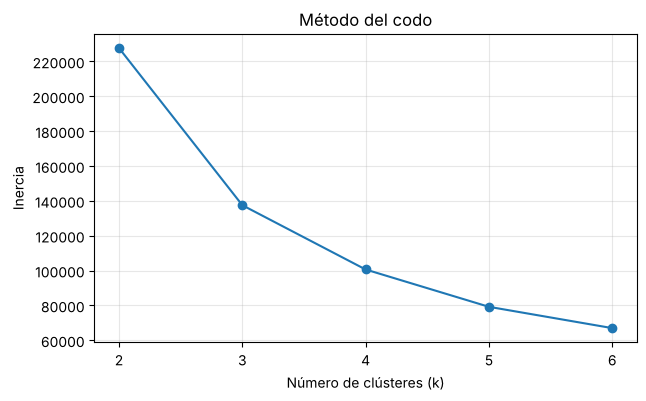

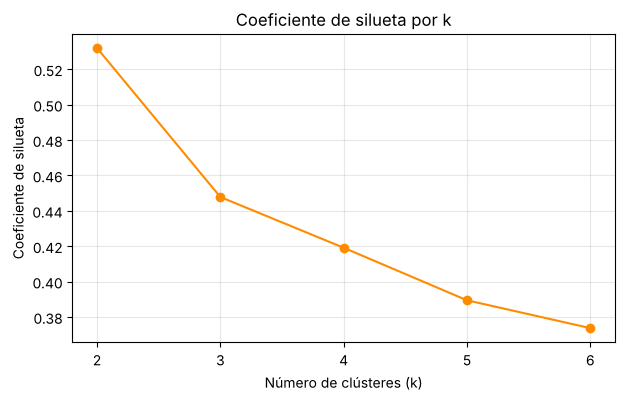

In [5]:
# 5. Evaluación del número de clústeres
valores_k = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas, sample_size=5000, random_state=42))

tabla_k = pd.DataFrame({'k': valores_k, 'Inercia': inercias, 'Silueta': siluetas})
display(tabla_k.round(4))

# Gráfica del método del codo
plt.figure(figsize=(7, 4))
plt.plot(valores_k, inercias, marker='o')
plt.title('Método del codo')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.show()

# Gráfica del coeficiente de silueta
plt.figure(figsize=(7, 4))
plt.plot(valores_k, siluetas, marker='o', color='darkorange')
plt.title('Coeficiente de silueta por k')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Coeficiente de silueta')
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

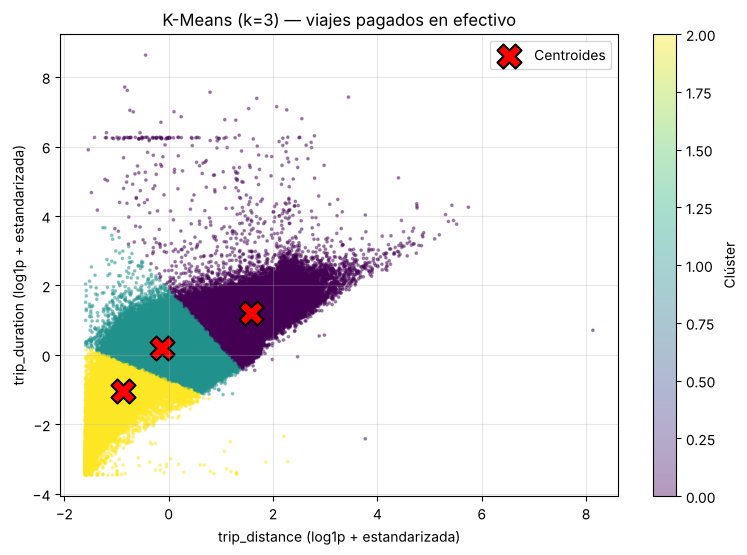

Viajes por clúster:
0     62395
1    125521
2     94169
Name: count, dtype: int64


In [6]:
# 6. Modelo final y visualización
k_final = 3
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas_final = kmeans_final.fit_predict(X_escalado)
centroides = kmeans_final.cluster_centers_

plt.figure(figsize=(9, 6))
sc = plt.scatter(X_escalado['trip_distance'], X_escalado['trip_duration'],
                 c=etiquetas_final, cmap='viridis', s=3, alpha=0.4)
plt.scatter(centroides[:, 0], centroides[:, 1], marker='X', s=300,
            c='red', edgecolors='black', linewidths=1.5, label='Centroides')
plt.colorbar(sc, label='Clúster')
plt.title(f'K-Means (k={k_final}) — viajes pagados en efectivo')
plt.xlabel('trip_distance (log1p + estandarizada)')
plt.ylabel('trip_duration (log1p + estandarizada)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print('Viajes por clúster:')
print(pd.Series(etiquetas_final).value_counts().sort_index())

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
# 7A. Estadísticos por clúster en unidades originales
df_resultado = df_cash.copy()
df_resultado['cluster'] = etiquetas_final

tabla_clusters = df_resultado.groupby('cluster').agg(
    cantidad_viajes=('trip_distance', 'count'),
    distancia_media_millas=('trip_distance', 'mean'),
    distancia_mediana_millas=('trip_distance', 'median'),
    duracion_media_min=('trip_duration', 'mean'),
    duracion_mediana_min=('trip_duration', 'median'),
).round(2)

display(tabla_clusters)

,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_min,duracion_mediana_min
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí **k = 3**. En la gráfica del codo, la inercia cae mucho de k=2 a k=3 (de 227,681 a 137,512, una reducción de aprox. 40 %), pero a partir de k=3 las reducciones son cada vez menores (100,620 en k=4, 79,205 en k=5 y 66,980 en k=6), así que el "codo" queda en k=3. La silueta más alta es la de k=2 (0.532), pero k=3 sigue teniendo una silueta aceptable (0.448), mayor que la de k=4, 5 y 6, que bajan a 0.42, 0.39 y 0.37. Además, con k=2 solo se separan viajes "cortos" y "largos", mientras que con k=3 aparecen tres grupos claros y fáciles de interpretar (cortos, medianos y largos), que responde mejor a la pregunta de qué tipos de viajes hay. Por eso k=3 es el mejor equilibrio entre compactación, separación e interpretación.


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**
- **Clúster 2 — "Viajes cortos / de cuadra"** (94,169 viajes): distancia media de 0.80 millas (mediana 0.76) y duración media de 5.72 min (mediana 5.82). Son trayectos muy breves dentro de una misma zona.
- **Clúster 1 — "Viajes urbanos medianos"** (125,521 viajes): distancia media de 2.30 millas (mediana 1.94) y duración media de 15.43 min (mediana 14.00). Son los traslados típicos dentro de la ciudad, entre barrios cercanos.
- **Clúster 0 — "Viajes largos / interurbanos o aeropuerto"** (62,395 viajes): distancia media de 11.55 millas (mediana 9.81) y duración media de 39.48 min (mediana 31.40). Son recorridos largos, probablemente hacia aeropuertos u otros distritos. En este grupo la media es bastante mayor que la mediana, lo que indica algunos viajes extremos (valores atípicos) que suben el promedio.


**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** El **clúster 0 ("viajes largos")** tiene la mayor duración promedio, 39.48 minutos, y **sí** es también el de mayor distancia promedio, 11.55 millas, muy por encima del clúster 1 (2.30 millas, 15.43 min) y del clúster 2 (0.80 millas, 5.72 min). Esto muestra que en los viajes en efectivo la duración y la distancia van de la mano: los grupos se ordenan igual en ambas variables (2 < 1 < 0).


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:** El grupo más numeroso es el **clúster 1 ("viajes urbanos medianos")** con 125,521 viajes, aprox. el 44.5 % de los 282,085 viajes en efectivo. En él predominan distancias cortas a moderadas, alrededor de 2 millas (media 2.30, mediana 1.94), y duraciones de unos 14-15 minutos (media 15.43, mediana 14.00). Media y mediana son parecidas, así que es un grupo bastante homogéneo: la mayoría de quienes pagan en efectivo hacen traslados urbanos cortos-medianos dentro de la ciudad.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**